# Records Request Data Cleaning & EDA

### Sidenote
Code cells involving data cleaning may be commented out to prevent creating files.

## I. Data Cleaning

### Background
The data to be cleaned is an excel file with one sheet per quarter per year for 2019~2021, plus one for several months of 2023. Of these, we will use the 8 sheets covering 2020 and 2021.

In [1]:
# Importing libraries and packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
#Creating a combined Pandas dataframe
"""
data_recordrequest = pd.read_excel("../data/Records.xlsx", sheet_name=None)
data_combined = pd.concat([
    data_recordrequest["Jan 1 - Mar 31 2020"],
    data_recordrequest["Apr 1 - Jun 30 2020"],
    data_recordrequest["Jul 1 - Sept 30 2020"],
    data_recordrequest["Oct 1 - Dec 31 2020"],
    data_recordrequest["Jan 1 - Mar 31 2021"],
    data_recordrequest["Apr 1 - Jun 30 2021"],
    data_recordrequest["Jul 1 - Sept 30 2021"],
    data_recordrequest["Oct 1 - Dec 31 2021"]
])
"""

The following cell can be run to read the cleaned data (resulting from this notebook) and avoid reading/writing other files.

In [47]:
data_combined = pd.read_csv("..\cleaned_data\Records_merged_cleaned.csv")

In [7]:
data_combined.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,OTCODE,DESCRIPTION,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
0,8645.0,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,2020-01-01,333,COMMUNITY MTG./EVENT,1200,1600,4.0,4.0
1,10738.0,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,2020-01-01,361,ADD. WORK ASSIGNED,1600,1800,2.0,2.0
2,11554.0,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,2020-01-01,256,EMERG. ITD SERVICE,1330,1430,1.0,1.0
3,9843.0,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,111,SICK LEAVE,1600,0,8.0,8.0
4,113177.0,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,220,SCHEDULED TOUR OF DU,0,400,4.0,4.0


In [ ]:
# Checking for duplicated rows
data_combined.duplicated().sum()

In [42]:
# Drop 'OTCODE'
"""
data_combined = data_combined.drop(labels=['OTCODE'], axis=1)
data_combined.head()
"""

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,DESCRIPTION,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
0,8645.0,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,2020-01-01,COMMUNITY MTG./EVENT,1200,1600,4.0,4.0
1,10738.0,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,2020-01-01,ADD. WORK ASSIGNED,1600,1800,2.0,2.0
2,11554.0,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,2020-01-01,EMERG. ITD SERVICE,1330,1430,1.0,1.0
3,9843.0,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,SICK LEAVE,1600,0,8.0,8.0
4,113177.0,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,SCHEDULED TOUR OF DU,0,400,4.0,4.0


In [44]:
data_combined.dtypes

IDNO6            float64
NAME              object
RANK              object
ASSIGNED_DESC     object
CHARGED_DESC      object
OTDATE            object
DESCRIPTION       object
STARTTIME          int64
ENDTIME            int64
WRKDHRS          float64
OTHOURS          float64
dtype: object

### Saving cleaned data

In [ ]:
# data_combined.to_csv("Records_merged_cleaned.csv", index=False)

## II. Exploring the Data

### Focus: Hours paid for but not worked
At the Boston Police Department, police officers who work overtime at **court** are paid 4 hours of overtime (at 1.5x their normal hourly pay rate).  
The **Records_merged_cleaned** data contains various types of overtime. Does something like court overtime happen in these other types?

Let us see how often the above happened 2020~2021.

In [8]:
data_combined = pd.read_csv("..\cleaned_data\Records_merged_cleaned.csv")

In [9]:
discrep = sum(data_combined["WRKDHRS"] != data_combined["OTHOURS"])
rowcount = data_combined.shape[0]
discrep, rowcount, discrep/rowcount

(26203, 406022, 0.06453591184714129)

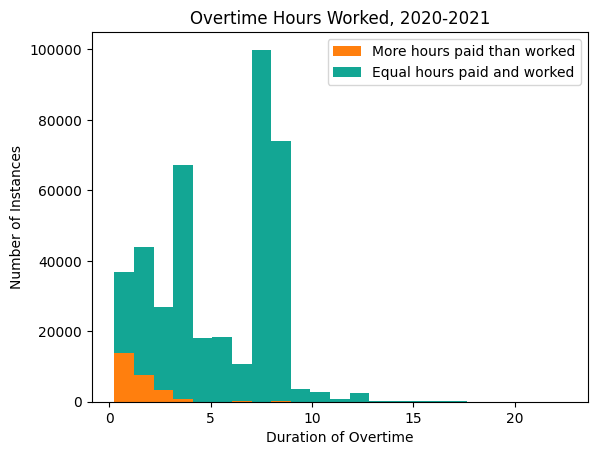

In [10]:
group_a = data_combined[data_combined["WRKDHRS"] < data_combined["OTHOURS"]]["WRKDHRS"]
group_b = data_combined[data_combined["WRKDHRS"] >= data_combined["OTHOURS"]]["WRKDHRS"]

plt.hist(
    [group_a, group_b], 
    bins=23, 
    stacked=True, 
    label=["More hours paid than worked", "Equal hours paid and worked"],
    color=['#ff7f0e', '#13a694']
)

plt.title("Overtime Hours Worked, 2020-2021")
plt.xlabel("Duration of Overtime")
plt.ylabel("Number of Instances")
plt.legend()

In [11]:
data_discrep = data_combined[data_combined["WRKDHRS"] != data_combined["OTHOURS"]]

In [12]:
data_discrep.head()

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,DESCRIPTION,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
43,11632.0,"Morrissey,James J",Det,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2020-01-01,EMERGENCY RECALLS,300,400,1.0,4.0
182,99778.0,"Nguyen,Chau V.",Ptl,VIDEO EVIDENCE UNIT,VIDEO EVIDENCE UNIT,2020-01-01,EMERG. ITD SERVICE,1600,1700,1.0,4.0
213,10745.0,"Wilson,Michael C",Ptl,PEER SUPPORT UNIT,FAMILY ASSISTANCE UNIT,2020-01-01,ADD. WORK ASSIGNED,2200,2330,1.5,4.0
237,11409.0,"Edghill-Yard,Susan R",SgtDet,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2020-01-01,EMERGENCY RECALLS,300,400,1.0,4.0
299,10238.0,"Acloque,Jean Moise",Det,B-3 DCU SQUAD,DRUG CONTROL UNIT,2020-01-02,COURT:CASE PREP.,1400,1530,1.5,4.0


In [13]:
pd.concat([data_discrep["RANK"].value_counts(), data_discrep["RANK"].value_counts()/data_combined["RANK"].value_counts()], axis=1)

,count,count
RANK,,
Ptl,12144.0,0.055621
Det,9104.0,0.123315
SgtDet,2234.0,0.073564
Sergt,1811.0,0.063384
LtDet,369.0,0.053610
Capt,306.0,0.048874
Lieut,235.0,0.025217
Civili,NaN,NaN
DepSup,NaN,NaN


In [14]:
data_discrep["ASSIGNED_DESC"].value_counts()

ASSIGNED_DESC
DISTRICT 02                    1723
DISTRICT 01                    1687
DOMESTIC VIOLENCE UNIT         1480
B-2   DETECTIVES               1460
DISTRICT 04                    1247
                               ... 
INVESTIGATIVE TRAINING UNIT       1
LEAVE OF ABSENCE SECTION          1
SCHOOL POLICE                     1
HACKNEY CARRIAGE UNIT             1
AUDITING AND REVIEW UNIT          1
Name: count, Length: 101, dtype: int64

In [15]:
data_discrep["OTHOURS"].value_counts().sort_index()

OTHOURS
4.0    25724
5.0        4
6.0        2
8.0      315
9.0      158
Name: count, dtype: int64

<Axes: >

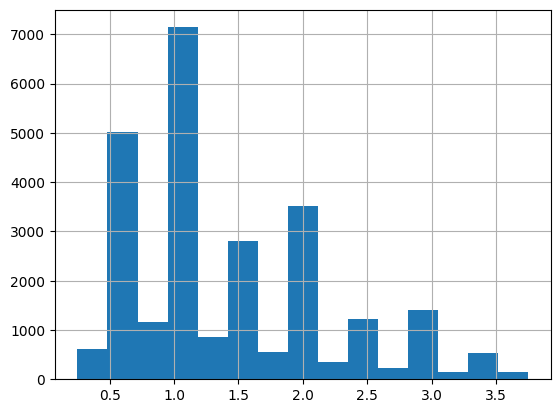

In [16]:
data_discrep[data_discrep["OTHOURS"] == 4.0]["WRKDHRS"].hist(bins=15)

In [17]:
sum(data_discrep["WRKDHRS"] > data_discrep["OTHOURS"])

0

In [18]:
data_court = data_combined[data_combined["DESCRIPTION"].str.contains('court', case=False, na=False)]

In [19]:
len(data_court) / len(data_combined)

0.04910571348350582

In [20]:
data_court.shape

(19938, 11)

In [21]:
len(data_court[data_court["WRKDHRS"] < 4.0]) / len(data_court)

0.9058080048149263

In [22]:
len(data_court[data_court["OTHOURS"] == 4.0]) / len(data_court)

0.9218076035710703

array([[<Axes: title={'center': 'WRKDHRS'}>,
        <Axes: title={'center': 'OTHOURS'}>]], dtype=object)

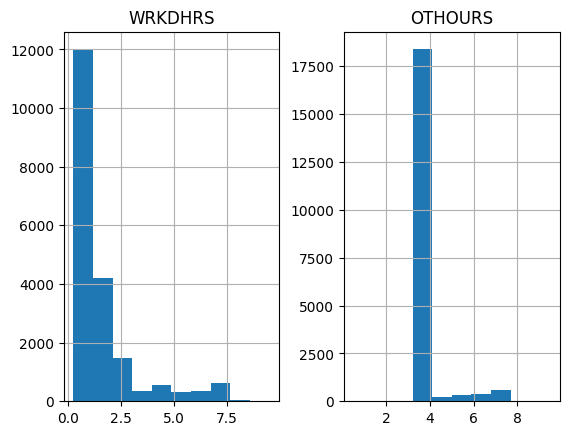

In [23]:
temp = data_court[["WRKDHRS", "OTHOURS"]]
temp.hist()

Text(0, 0.5, 'Number of instances')

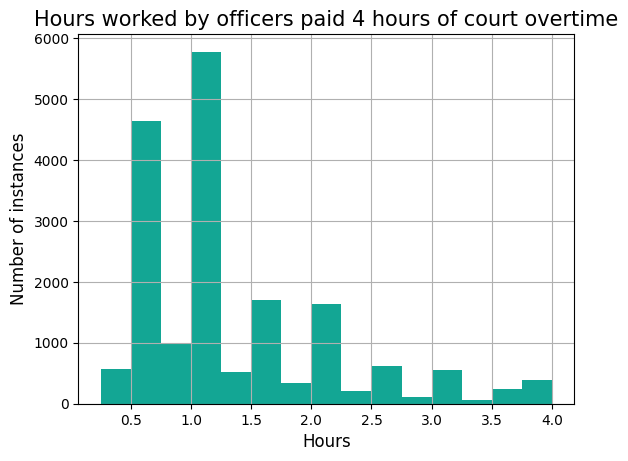

In [24]:
temp[temp["OTHOURS"] == 4.0]["WRKDHRS"].hist(bins=15, color='#13a694')
plt.title("Hours worked by officers paid 4 hours of court overtime", fontsize=15)
plt.xlabel("Hours", fontsize=12)
plt.ylabel("Number of instances", fontsize=12)

In [25]:
len(temp[(temp["OTHOURS"] == 4.0) & (temp["WRKDHRS"] < 4.0)]) / len(temp["OTHOURS"] == 4.0)

0.9041027184271241

In [26]:
len(temp[temp["OTHOURS"] > temp["WRKDHRS"]]) / len(temp)

0.9041027184271241

In [27]:
len(temp[(temp["OTHOURS"] == 4.0) & (temp["WRKDHRS"] == 4.0)]) / len(temp["OTHOURS"] == 4.0)

0.017704885143946233

In [28]:
sum(temp["OTHOURS"] == 4.0)

18379

In [29]:
sum((temp["WRKDHRS"] < 4.0) & (temp["OTHOURS"] == 4.0)) / sum(temp["OTHOURS"] == 4.0)

0.9807932966973176

In [30]:
sum(temp["WRKDHRS"] < 4.0) / len(temp)

0.9058080048149263

In [31]:
sum((temp["WRKDHRS"] < 4.0) & (temp["OTHOURS"] > 4.0))

0

In [32]:
sum(temp["OTHOURS"] < 4.0)

34

array([[<Axes: title={'center': 'WRKDHRS'}>]], dtype=object)

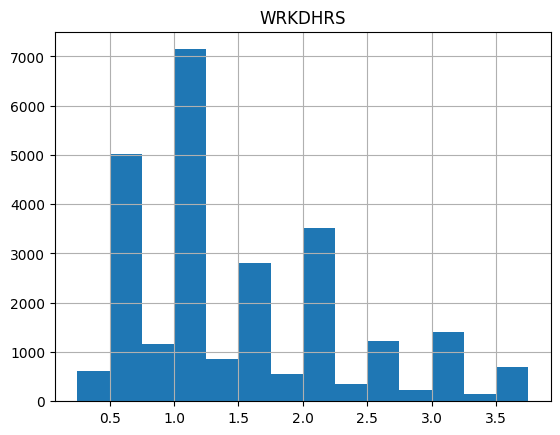

In [33]:
data_discrep[data_discrep["WRKDHRS"] < 4][["WRKDHRS"]].hist(bins=14)

In [34]:
data_combined["DESCRIPTION"].unique()

array(['COMMUNITY MTG./EVENT', 'ADD. WORK ASSIGNED', 'EMERG. ITD SERVICE',
       'SICK LEAVE', 'SCHEDULED TOUR OF DU', 'SCHED. TELECOMM SERV',
       'ADMIN. DIV/UNIT', 'INSTRUCTOR: ACADEMY', 'EMERG. BLDG REPAIRS',
       'CRIME SCENE INVEST.', 'SEARCH WARRANT', 'FIRST NIGHT',
       'INVESTIGATION (CC#)', 'INJURED LEAVE', 'VACATION LEAVE',
       'PL DAY (sworn)', 'EMERGENCY RECALLS', 'WO DAY [sworn]', 'E DAY',
       'MASS / MELNEA', 'UNION:GRIEV. PREP.', 'DIRECTED PATROL',
       'COMPLETE TOUR ASSIGN', 'GANG CAR', 'DAYS OFF',
       "CRIT.INC.:ADD'D PAT.", 'C DAY', 'INSTRUCTOR: RANGE',
       'MILT. LEAVE/TRAINING', 'COMMUNITY MEETING/EV',
       'SPECIAL INVESTIGATIO', 'F.D.I.T.', 'BEAT TEAM MEETING',
       'ADMIN. COMMANDER', 'ENTRY TEAM', 'IN-SERVICE TRAINING',
       'SCHED. FLEET SERVICE', 'RADIO PROJECT BLU', 'COURT:CASE PREP.',
       'COURT:CLERK MAG. HRG', 'COURT:PRETRIAL CONF.',
       'COURT:MOTIONS HRG.', 'COURT:TRIAL', 'DIGN. PROTECT/ESCORT',
       'PR:CI.STRESS DEB

In [35]:
data_combined["DESCRIPTION"].value_counts().head(15)

DESCRIPTION
INVESTIGATION (CC#)     52761
INJURED LEAVE           41096
PROTEST RESPONSE        27110
ADD. WORK ASSIGNED      22157
COMPLETE TOUR ASSIGN    20681
VACATION LEAVE          18835
SICK LEAVE              17728
MASS / MELNEA           14062
GANG CAR                11924
SCHEDULED TOUR OF DU    11619
ELECTION COVERAGE       10088
DIRECTED PATROL          9525
ADMIN. DIV/UNIT          9323
COVID-19 - REPLACEME     7964
SPECIAL INVESTIGATIO     7528
Name: count, dtype: int64

In [36]:
data_notcourt = data_combined[~data_combined["DESCRIPTION"].str.contains('court', case=False, na=False)]
data_notcourt

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,DESCRIPTION,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
0,8645.0,"Gillespie,Joseph G.",Capt,DISTRICT 18,DISTRICT 18,2020-01-01,COMMUNITY MTG./EVENT,1200,1600,4.00,4.00
1,10738.0,"Sexton,Richard",Capt,CRIMINAL INVESTIGATIVE DIV.,CRIMINAL INVESTIGATIVE DIV.,2020-01-01,ADD. WORK ASSIGNED,1600,1800,2.00,2.00
2,11554.0,"Barcelou,Brian R",Civili,INFORMATION SYSTEMS GROUP,INFORMATION SYSTEMS GROUP,2020-01-01,EMERG. ITD SERVICE,1330,1430,1.00,1.00
3,9843.0,"Bynoe,Sonya D",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,SICK LEAVE,1600,0,8.00,8.00
4,113177.0,"Cardona,Veronica",Civili,OPERATIONS DIVISION,OPERATIONS DIVISION,2020-01-01,SCHEDULED TOUR OF DU,0,400,4.00,4.00
...,...,...,...,...,...,...,...,...,...,...,...
406017,11359.0,"Rouvalis,John A",SgtDet,E-18 DETECTIVES,E-18 DETECTIVES,2021-12-31,SCHEDULED TOUR OF DU,730,1600,8.50,8.50
406018,75928.0,"Sellon,Jacqueline A",SgtDet,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2021-12-31,EMERGENCY RECALLS,530,830,3.00,4.00
406019,88314.0,"Teixeira,Jose M",SgtDet,INTELLIGENCE GROUP,SPECIAL EVENTS,2021-12-31,FIRST NIGHT,1600,100,9.00,9.00
406020,10597.0,"Troy,Anthony E.",SgtDet,E-5 DCU SQUAD,SPECIAL EVENTS,2021-12-31,FIRST NIGHT,2345,345,4.00,4.00


In [37]:
data_notcourt["DESCRIPTION"].value_counts()

DESCRIPTION
INVESTIGATION (CC#)     52761
INJURED LEAVE           41096
PROTEST RESPONSE        27110
ADD. WORK ASSIGNED      22157
COMPLETE TOUR ASSIGN    20681
                        ...  
DORCHESTER DAY PARAD        1
OUTSIDE THE BOX             1
LIGHT. TRUCK CALLOUT        1
AIDS WALK                   1
CRIT.INC.:INFRASTRUC        1
Name: count, Length: 185, dtype: int64

In [38]:
discrep_notcourt = data_notcourt[data_notcourt["OTHOURS"] > data_notcourt["WRKDHRS"]]
discrep_notcourt

,IDNO6,NAME,RANK,ASSIGNED_DESC,CHARGED_DESC,OTDATE,DESCRIPTION,STARTTIME,ENDTIME,WRKDHRS,OTHOURS
43,11632.0,"Morrissey,James J",Det,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2020-01-01,EMERGENCY RECALLS,300,400,1.00,4.0
182,99778.0,"Nguyen,Chau V.",Ptl,VIDEO EVIDENCE UNIT,VIDEO EVIDENCE UNIT,2020-01-01,EMERG. ITD SERVICE,1600,1700,1.00,4.0
213,10745.0,"Wilson,Michael C",Ptl,PEER SUPPORT UNIT,FAMILY ASSISTANCE UNIT,2020-01-01,ADD. WORK ASSIGNED,2200,2330,1.50,4.0
237,11409.0,"Edghill-Yard,Susan R",SgtDet,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2020-01-01,EMERGENCY RECALLS,300,400,1.00,4.0
571,12269.0,"Lane,Frederick D",Ptl,DISTRICT 07,DISTRICT 07,2020-01-02,DIRECTED PATROL,730,1030,3.00,4.0
...,...,...,...,...,...,...,...,...,...,...,...
405423,98643.0,"Rooney,Mary M.",Det,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2021-12-31,EMERGENCY RECALLS,540,830,3.00,4.0
405467,74887.0,"Leary,Beth",LtDet,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2021-12-31,EMERGENCY RECALLS,700,845,1.75,4.0
405763,132363.0,"Mendes,Kevin",Ptl,DISTRICT 02,DISTRICT 02,2021-12-31,DIRECTED PATROL,2045,2315,2.50,4.0
405988,8765.0,"Barker,Gary",SgtDet,SEXUAL ASSAULT UNIT,SEXUAL ASSAULT UNIT,2021-12-31,EMERGENCY RECALLS,345,445,1.00,4.0


In [39]:
discrep_notcourt["DESCRIPTION"].value_counts().head(20)

DESCRIPTION
EMERGENCY RECALLS       1833
COMMUNITY MEETING/EV    1047
INVESTIGATION (CC#)      870
PROBATION HEARING        604
ADD. WORK ASSIGNED       548
PR:CI.STRESS DEBRIEF     376
LABOR DISP PO DET        332
ADMIN. HEARING           269
ENTRY TEAM               232
EMERG. ITD SERVICE       230
CRIME SCENE INVEST.      219
INSTRUCTOR: ACADEMY      148
DIRECTED PATROL          122
ADMIN. DIV/UNIT          116
BWC - ADDTL TOUR / C     112
LABOR DISP SERGEANT      111
PROTEST RESPONSE         103
COVID-19 - ADDTL TOU      96
DIGN. PROTECT/ESCORT      89
ADMIN. COMMANDER          79
Name: count, dtype: int64

In [40]:
sum(discrep_notcourt[discrep_notcourt["DESCRIPTION"] == "EMERGENCY RECALLS"]["ASSIGNED_DESC"] == "SEXUAL ASSAULT UNIT") / len(discrep_notcourt[discrep_notcourt["DESCRIPTION"] == "EMERGENCY RECALLS"])

0.14511729405346427

In [ ]:
data_discrep["WRKDHRS"]